In [4]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/EN3150_A03
!ls

Mounted at /content/drive
/content/drive/MyDrive/EN3150_A03
Data_loader.py	NodeConvs_A_Net.py  SOTA_Finetune.py
Data_prep.py	NodeConvs_B_Net.py  Train.py


In [4]:
!nvidia-smi
!pip install -q --upgrade medmnist

Mon Oct 12 09:54:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
!nvidia-smi
!pip install -q --upgrade medmnist

Mon Oct 12 10:18:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [6]:
!mkdir -p BloodMNIST
!cd BloodMNIST && python ../Data_prep.py
!ls BloodMNIST

100% 156M/156M [04:10<00:00, 624kB/s]
Train:  11959 images  (70.0%)
Val:     2566 images  (15.0%)
Test:    2567 images  (15.0%)
Saved custom split -> bloodmnist_70_15_15.npz
bloodmnist_70_15_15.npz


In [7]:
!grep -n "import" Train.py | head -5

1:from NodeConvs_A_Net import NodeConvs_Net
2:from NodeConvs_B_Net import NodeConvs_B_Net
3:from Data_loader import get_dataloaders
4:import torch
5:import torch.nn as nn


In [8]:
!python SOTA_Finetune.py

Using device: cuda

Fine-tuning MobileNetV2
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth
100% 13.6M/13.6M [00:00<00:00, 117MB/s] 
Training Model MobileNetV2 with 10,248 trainable parameters.
Epoch  1/5 | Train Loss: 0.6891 | train_Acc: 0.7801 || Val Loss: 0.4488 | Val_Acc: 0.8609 | AUC: 0.9820 | F1: 0.8401 | Time: 6.2s
Epoch  2/5 | Train Loss: 0.4641 | train_Acc: 0.8486 || Val Loss: 0.4326 | Val_Acc: 0.8652 | AUC: 0.9827 | F1: 0.8422 | Time: 5.0s
Epoch  3/5 | Train Loss: 0.4205 | train_Acc: 0.8573 || Val Loss: 0.3898 | Val_Acc: 0.8741 | AUC: 0.9845 | F1: 0.8543 | Time: 3.4s
Epoch  4/5 | Train Loss: 0.4153 | train_Acc: 0.8609 || Val Loss: 0.3834 | Val_Acc: 0.8737 | AUC: 0.9854 | F1: 0.8547 | Time: 3.4s
Epoch  5/5 | Train Loss: 0.4045 | train_Acc: 0.8589 || Val Loss: 0.3862 | Val_Acc: 0.8737 | AUC: 0.9849 | F1: 0.8520 | Time: 4.8s

Best Validation Macro f1: 0.8547
Average Training Time / Epoch

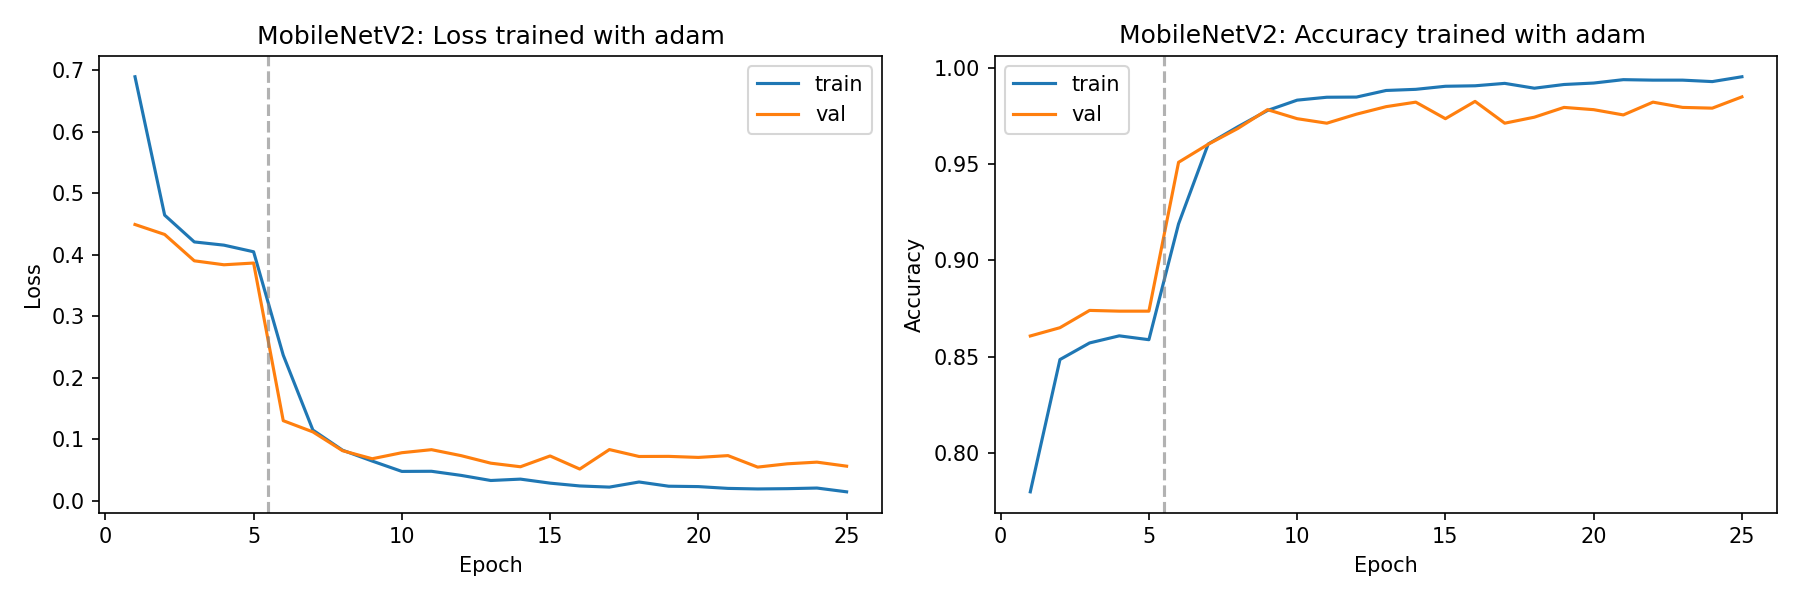

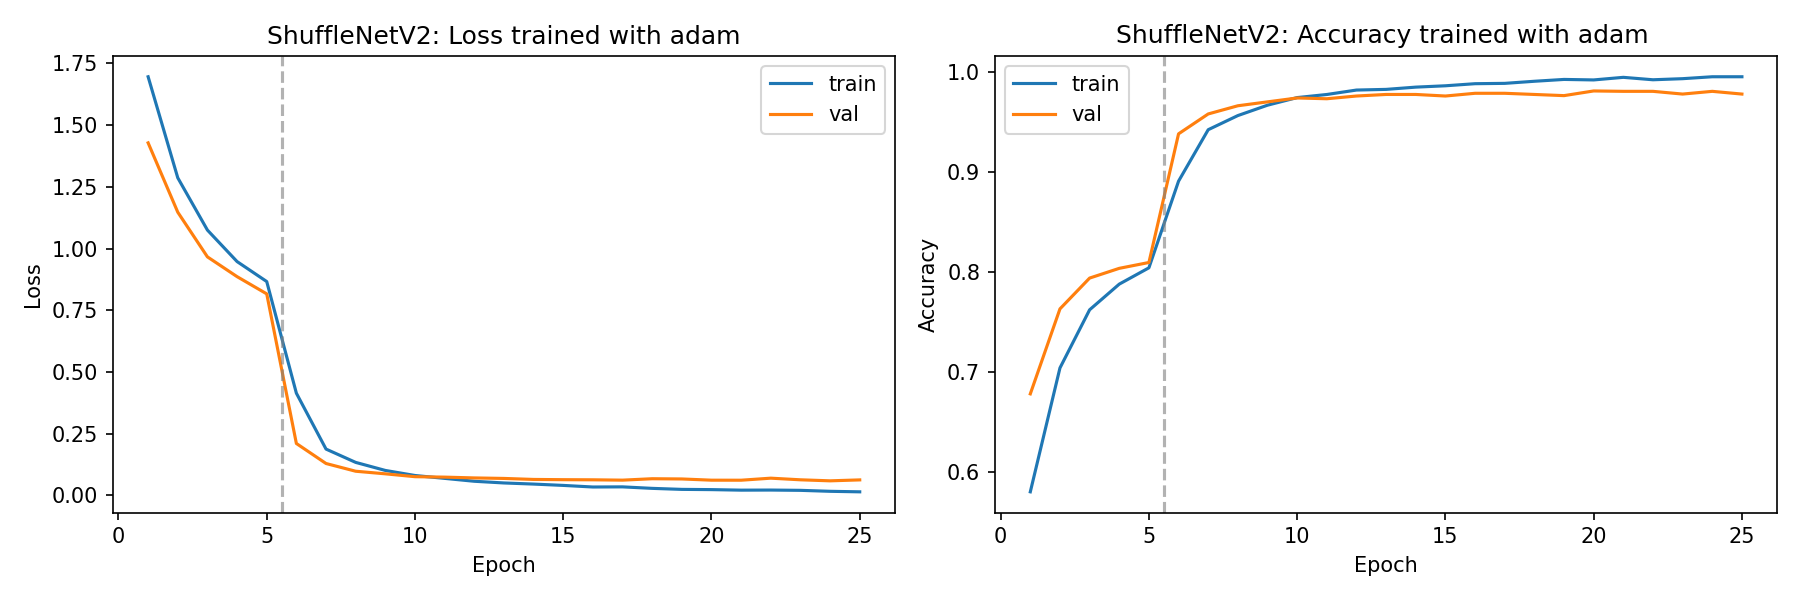

In [9]:
from IPython.display import Image, display
display(Image("Weights/MobileNetV2.png"))
display(Image("Weights/ShuffleNetV2.png"))